In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.19.1


In [29]:
train = pd.read_csv("FNN and CNN/HandWritten MNIST/mnist_train.csv")
test = pd.read_csv("FNN and CNN/HandWritten MNIST/mnist_test.csv")

x_train = train.iloc[:, 1:].values / 255.0
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values / 255.0
y_test = test.iloc[:, 0].values

In [30]:
print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

Training images: (60000, 784)
Testing images: (10000, 784)


In [31]:
model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [33]:
history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 657us/step - accuracy: 0.8259 - loss: 0.7031 - val_accuracy: 0.9162 - val_loss: 0.3261
Epoch 2/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 624us/step - accuracy: 0.9019 - loss: 0.3535 - val_accuracy: 0.9315 - val_loss: 0.2594
Epoch 3/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 601us/step - accuracy: 0.9153 - loss: 0.3013 - val_accuracy: 0.9368 - val_loss: 0.2319
Epoch 4/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 630us/step - accuracy: 0.9240 - loss: 0.2700 - val_accuracy: 0.9418 - val_loss: 0.2110
Epoch 5/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 616us/step - accuracy: 0.9307 - loss: 0.2471 - val_accuracy: 0.9477 - val_loss: 0.1932
Epoch 6/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 805us/step - accuracy: 0.9362 - loss: 0.2282 - val_accuracy: 0.9515 - val_loss: 0.1805
Epoch 7/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 612us/step - accuracy: 0.9413 - loss: 0.2125 - val_accuracy: 0.9540 - val_loss: 0.1701
Epoch 8/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 1s 679us/step - accuracy: 0.9443 -

In [34]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test Loss: 0.1632
Test Accuracy: 95.22 %


In [35]:
prediction = model.predict(x_test[:1], verbose=0)

predicted_digit = prediction.argmax(axis=1)[0]

print("Predicted digit:", predicted_digit)
print("Actual digit:", y_test[0])

Predicted digit: 7
Actual digit: 7


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


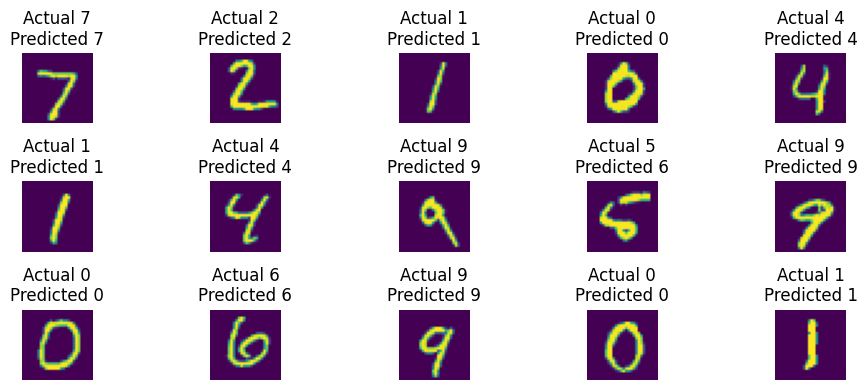

In [36]:
prediction = model.predict(x_test[:15])

predicted_digit = prediction.argmax(axis = 1)

plt.figure(figsize=(10 , 4))
for i in range(15):
    plt.subplot(3 , 5 , i+1)
    plt.imshow(x_test[i].reshape(28 , 28))
    plt.title(f"Actual {y_test[i]}\nPredicted {predicted_digit[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


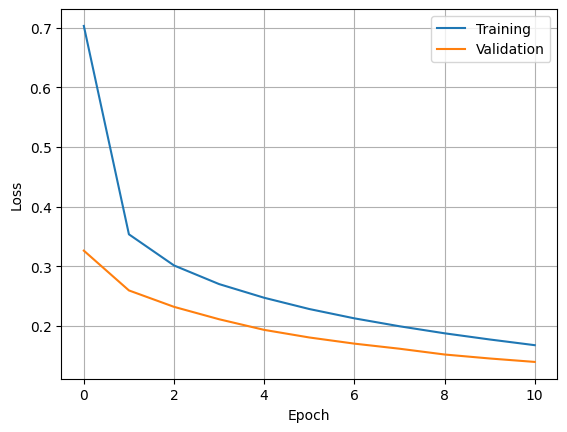

In [37]:
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

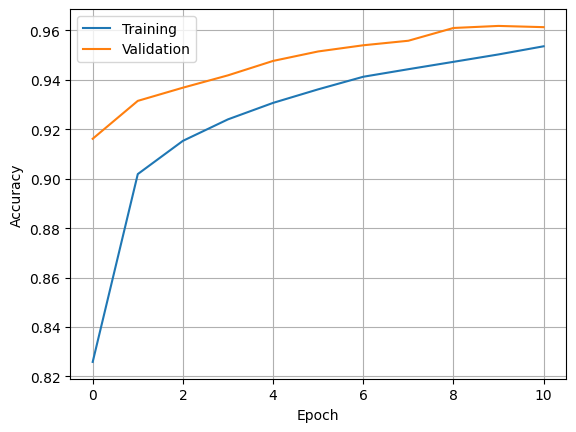

In [38]:
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()